# Linear Regression manual class test

##### _The purpose of this notebook is test my manual linear model class and compare it against Python's statsmodels library_

My goals are to compare:
- Regression coefficients
- Standard errors and p-values
- R-squared and adjusted R-squared
- Confidence and prediction intervals
- Variance Inflation Factor (VIF)
- Model execution time


In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import time
from lm_manual_class import lm_manual
from statsmodels.stats.outliers_influence import variance_inflation_factor


#### Simple linear model tests

For our first tests we are going to be testing on a simple linear model with one predictor 

In [143]:
# Generate some synthetic data first
rng = np.random.default_rng(42)
n = 100_000
x = rng.normal(50, 10, n)
error = rng.normal(0, 15, n)
y = 20 + 2.5 * x + error
df = pd.DataFrame({
    "x": x,
    "y": y
})
df.head()

,x,y
0,53.047171,128.998933
1,39.600159,154.863609
2,57.504512,190.705909
3,59.405647,156.084051
4,30.489648,120.244977


#### **Test #1:** Compare Summaries of both stats model and lm_manual

In [144]:
# statsmodels regression

X = sm.add_constant(df["x"])
sm_model = sm.OLS(df["y"], X).fit()
sm_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.736
Model:                            OLS   Adj. R-squared:                  0.736
Method:                 Least Squares   F-statistic:                 2.786e+05
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:25:37   Log-Likelihood:            -4.1288e+05
No. Observations:              100000   AIC:                         8.258e+05
Df Residuals:                   99998   BIC:                         8.258e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         20.1019      0.241     83.325      0.000      19.629      20.575
x              2.4988      0.005    527.790      0.000       2.489       2.508
==============================================================================
Omnibus:                        4.691   Durbin-Watson:                   2.006
Prob(Omnibus):                  0.096   Jarque-Bera (JB):                4.683
Skew:                           0.015   Prob(JB):                       0.0962
Kurtosis:                       3.016   Cond. No.                         259.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [145]:
# lm_manual regression

lm_custom = lm_manual(df["x"], df["y"])

OLS Summary:
------------------------------------------------------------------------------------------------------------
Response variable:   y
Predictors:          1
Observations used:   100000
Rows removed:        0
------------------------------------------------------------------------------------------------------------
Coefficient Estimates
Term                  Estimate    Std. Error     t value       P-value                        95% CI
------------------------------------------------------------------------------------------------------------
Intercept              20.1019        0.2412     83.3252             0            (19.6291, 20.5748)
x                       2.4988        0.0047    527.7898             0              (2.4895, 2.5081)
------------------------------------------------------------------------------------------------------------
Residual standard error: 15.0270 on 99998 degrees of freedom
R-squared: 0.7358, Adjusted R-squared: 0.7358
F-statistic: 278562.08

In [146]:
# Compare the statistics

summary_comparison = pd.DataFrame({
    "My Class": [
        lm_custom.R_squared,
        lm_custom.adjusted_r_squared,
        lm_custom.rse,
        lm_custom.f_stat,
        lm_custom.p_value
    ],
    "Statsmodels": [
        sm_model.rsquared,
        sm_model.rsquared_adj,
        np.sqrt(sm_model.mse_resid),
        sm_model.fvalue,
        sm_model.f_pvalue
    ]
}, index=[
    "R-squared",
    "Adjusted R-squared",
    "Residual Standard Error",
    "F-statistic",
    "P-value"
])

summary_comparison

,My Class,Statsmodels
R-squared,0.735846,0.735846
Adjusted R-squared,0.735844,0.735844
Residual Standard Error,15.026977,15.026977
F-statistic,278562.087695,278562.087695
P-value,0.000000,0.000000


#### **Test #1** results:

Both my custom lm_manual class and the statsmodels OLS implementation produced matching regression results when fitted using the same dataset.

The coefficient estimates, standard errors, p-values, R-squared, and F-statistics were consistent between the two models.

**Conclusion:** Test #1 passed. My custom implementation produces results consistent with statsmodels for simple linear regression.

#### **Test #2:** Compare Summaries of both statsmodels and lm_manual with missing values

In [147]:
# Create a copy of previous data with some missing values

df_missing = df.copy()
df_missing.loc[rng.random(n) < 0.10, "x"] = np.nan
df_missing.loc[rng.random(n) < 0.05, "y"] = np.nan

In [148]:
# Statsmodels regression with missing values

X = sm.add_constant(df_missing["x"])
sm_model_missing = sm.OLS(df_missing["y"], X, missing="drop").fit()
sm_model_missing.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.736
Model:                            OLS   Adj. R-squared:                  0.736
Method:                 Least Squares   F-statistic:                 2.383e+05
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:25:37   Log-Likelihood:            -3.5290e+05
No. Observations:               85462   AIC:                         7.058e+05
Df Residuals:                   85460   BIC:                         7.058e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         20.0281      0.261     76.726      0.000      19.516      20.540
x              2.5001      0.005    488.125      0.000       2.490       2.510
==============================================================================
Omnibus:                        1.109   Durbin-Watson:                   2.006
Prob(Omnibus):                  0.574   Jarque-Bera (JB):                1.098
Skew:                           0.005   Prob(JB):                        0.578
Kurtosis:                       3.015   Cond. No.                         259.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [149]:
# manual_lm regression with missing values

lm_custom_missing = lm_manual(df_missing["x"], df_missing["y"])

OLS Summary:
------------------------------------------------------------------------------------------------------------
Response variable:   y
Predictors:          1
Observations used:   85462
Rows removed:        14538
------------------------------------------------------------------------------------------------------------
Coefficient Estimates
Term                  Estimate    Std. Error     t value       P-value                        95% CI
------------------------------------------------------------------------------------------------------------
Intercept              20.0281        0.2610     76.7259             0            (19.5165, 20.5397)
x                       2.5001        0.0051    488.1253             0              (2.4901, 2.5102)
------------------------------------------------------------------------------------------------------------
Residual standard error: 15.0354 on 85460 degrees of freedom
R-squared: 0.7360, Adjusted R-squared: 0.7360
F-statistic: 238266

In [150]:
# Compare the statistics

summary_comparison_missing = pd.DataFrame({
    "My Class": [
        lm_custom_missing.R_squared,
        lm_custom_missing.adjusted_r_squared,
        lm_custom_missing.rse,
        lm_custom_missing.f_stat,
        lm_custom.p_value
    ],
    "Statsmodels": [
        sm_model_missing.rsquared,
        sm_model_missing.rsquared_adj,
        np.sqrt(sm_model_missing.mse_resid),
        sm_model_missing.fvalue,
        sm_model_missing.f_pvalue
    ]
}, index=[
    "R-squared",
    "Adjusted R-squared",
    "Residual Standard Error",
    "F-statistic",
    "P-value"
])

summary_comparison_missing

,My Class,Statsmodels
R-squared,0.736012,0.736012
Adjusted R-squared,0.736009,0.736009
Residual Standard Error,15.035409,15.035409
F-statistic,238266.333923,238266.333923
P-value,0.000000,0.000000


#### **Test #2** results:

Both my custom lm_manual class and the Statsmodels OLS implementation produced matching regression results when fitted using the dataset containing missing values.

The coefficient estimates, standard errors, p-values, R-squared, adjusted R-squared, residual standard error, and F-statistics were consistent between the two models after handling the missing observations.

**Conclusion:** Test #2 passed. My custom implementation handles missing values correctly and produces results consistent with Statsmodels for simple linear regression

#### **Test #3**: Compare prediction intervals of both statsmodels and lm_manual


In [151]:
x_new = np.array([20, 30, 40, 50, 60, 70, 80])
# My class
my_pred = lm_custom.predict(x_new)
my_ci = lm_custom.predict(x_new, interval="CONFIDENCE")
my_pi = lm_custom.predict(x_new, interval="PREDICTION")
# Statsmodels
X_new = sm.add_constant(x_new)
sm_results = sm_model.get_prediction(X_new).summary_frame(alpha=0.05)
# Comparison DataFrame
comparison = pd.DataFrame({
    "X": x_new,

    "My Prediction": np.asarray(my_pred).ravel(),
    "SM Prediction": sm_results["mean"].to_numpy(),

    "My CI Lower": my_ci["Lower Bound"].to_numpy(),
    "SM CI Lower": sm_results["mean_ci_lower"].to_numpy(),

    "My CI Upper": my_ci["Upper Bound"].to_numpy(),
    "SM CI Upper": sm_results["mean_ci_upper"].to_numpy(),

    "My PI Lower": my_pi["Lower Bound"].to_numpy(),
    "SM PI Lower": sm_results["obs_ci_lower"].to_numpy(),

    "My PI Upper": my_pi["Upper Bound"].to_numpy(),
    "SM PI Upper": sm_results["obs_ci_upper"].to_numpy()
})

comparison.round(4)

,X,My Prediction,SM Prediction,My CI Lower,SM CI Lower,My CI Upper,SM CI Upper,My PI Lower,SM PI Lower,My PI Upper,SM PI Upper
0,20,70.0774,70.0774,69.7843,69.7843,70.3706,70.3706,40.6233,40.6233,99.5316,99.5316
1,30,95.0652,95.0652,94.8579,94.8579,95.2725,95.2725,65.6118,65.6118,124.5186,124.5186
2,40,120.0530,120.0530,119.9218,119.9218,120.1841,120.1841,90.6000,90.6000,149.5059,149.5059
3,50,145.0407,145.0407,144.9476,144.9476,145.1338,145.1338,115.5879,115.5879,174.4935,174.4935
4,60,170.0285,170.0285,169.8967,169.8967,170.1602,170.1602,140.5755,140.5755,199.4814,199.4814
5,70,195.0162,195.0162,194.8082,194.8082,195.2242,195.2242,165.5628,165.5628,224.4696,224.4696
6,80,220.0040,220.0040,219.7101,219.7101,220.2979,220.2979,190.5498,190.5498,249.4581,249.4581


#### **Test #3** results:
Both my custom lm_manual class and the Statsmodels OLS implementation produced matching point predictions, confidence intervals, and prediction intervals when evaluated using the same independent variable values.

All predicted values, confidence interval bounds, and prediction interval bounds were identical to four decimal places across the seven tested observations.

**Conclusion:** Test #3 passed. My custom implementation accurately calculates point predictions, confidence intervals, and prediction intervals consistent with Statsmodels for simple linear regression.

#### **Test #4:** Compare diagnostics of both statsmodels and lm_manul

In [152]:
# My class diagnostics
my_fitted = lm_custom.fitted_y
my_resid = lm_custom.residuals
my_leverage = lm_custom.leverage
my_std_resid = lm_custom.std_residuals
my_cooks = lm_custom.cooks_distance

# Statsmodels diagnostics
sm_influence = sm_model.get_influence()

sm_fitted = sm_model.fittedvalues
sm_resid = sm_model.resid
sm_leverage = sm_influence.hat_matrix_diag
sm_std_resid = sm_influence.resid_studentized_internal
sm_cooks = sm_influence.cooks_distance[0]

diagnostics_comparison = pd.DataFrame({
    "My Fitted": np.asarray(my_fitted).ravel(),
    "SM Fitted": np.asarray(sm_fitted).ravel(),

    "My Residual": np.asarray(my_resid).ravel(),
    "SM Residual": np.asarray(sm_resid).ravel(),

    "My Leverage": np.asarray(my_leverage).ravel(),
    "SM Leverage": np.asarray(sm_leverage).ravel(),

    "My Std Residual": np.asarray(my_std_resid).ravel(),
    "SM Std Residual": np.asarray(sm_std_resid).ravel(),

    "My Cook's D": np.asarray(my_cooks).ravel(),
    "SM Cook's D": np.asarray(sm_cooks).ravel()
})

diagnostics_comparison.head(10).round(6)

,My Fitted,SM Fitted,My Residual,SM Residual,My Leverage,SM Leverage,My Std Residual,SM Std Residual,My Cook's D,SM Cook's D
0,152.654904,152.654904,-23.655971,-23.655971,0.000011,0.000011,-1.574242,-1.574242,0.000014,0.000014
1,119.053837,119.053837,35.809771,35.809771,0.000021,0.000021,2.383057,2.383057,0.000059,0.000059
2,163.792799,163.792799,26.913109,26.913109,0.000016,0.000016,1.791000,1.791000,0.000025,0.000025
3,168.543310,168.543310,-12.459259,-12.459259,0.000019,0.000019,-0.829134,-0.829134,0.000006,0.000006
4,96.288714,96.288714,23.956263,23.956263,0.000048,0.000048,1.594255,1.594255,0.000061,0.000061
5,112.502162,112.502162,-17.308559,-17.308559,0.000027,0.000027,-1.151848,-1.151848,0.000018,0.000018
6,148.235152,148.235152,-10.144934,-10.144934,0.000010,0.000010,-0.675118,-0.675118,0.000002,0.000002
7,137.138514,137.138514,0.099390,0.099390,0.000011,0.000011,0.006614,0.006614,0.000000,0.000000
8,144.620884,144.620884,-13.188555,-13.188555,0.000010,0.000010,-0.877663,-0.877663,0.000004,0.000004
9,123.725053,123.725053,9.030870,9.030870,0.000017,0.000017,0.600982,0.600982,0.000003,0.000003


#### **Test #4** Results:

Both my custom lm_manual class and the Statsmodels OLS implementation produced matching regression diagnostic statistics when evaluated using the same dataset.

The fitted values, residuals, leverage values, standardized residuals, and Cook's distances were consistent between both models to six decimal places for the observations examined.

**Conclusion:** Test #4 passed for the displayed observations. My custom implementation accurately calculates regression diagnostics consistent with Statsmodels for simple linear regression.

#### **Test #5:** Test both plot_regression and plot_diagonistcs of lm_manual

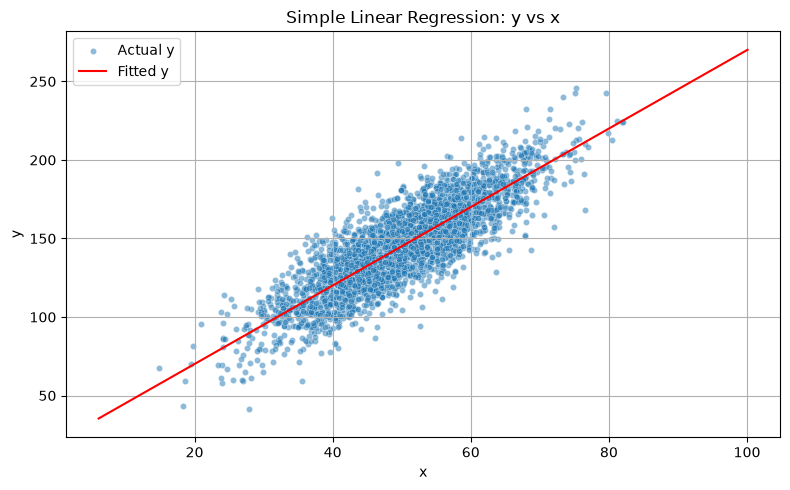

In [153]:
# Plot regression method

lm_custom.plot_regression()

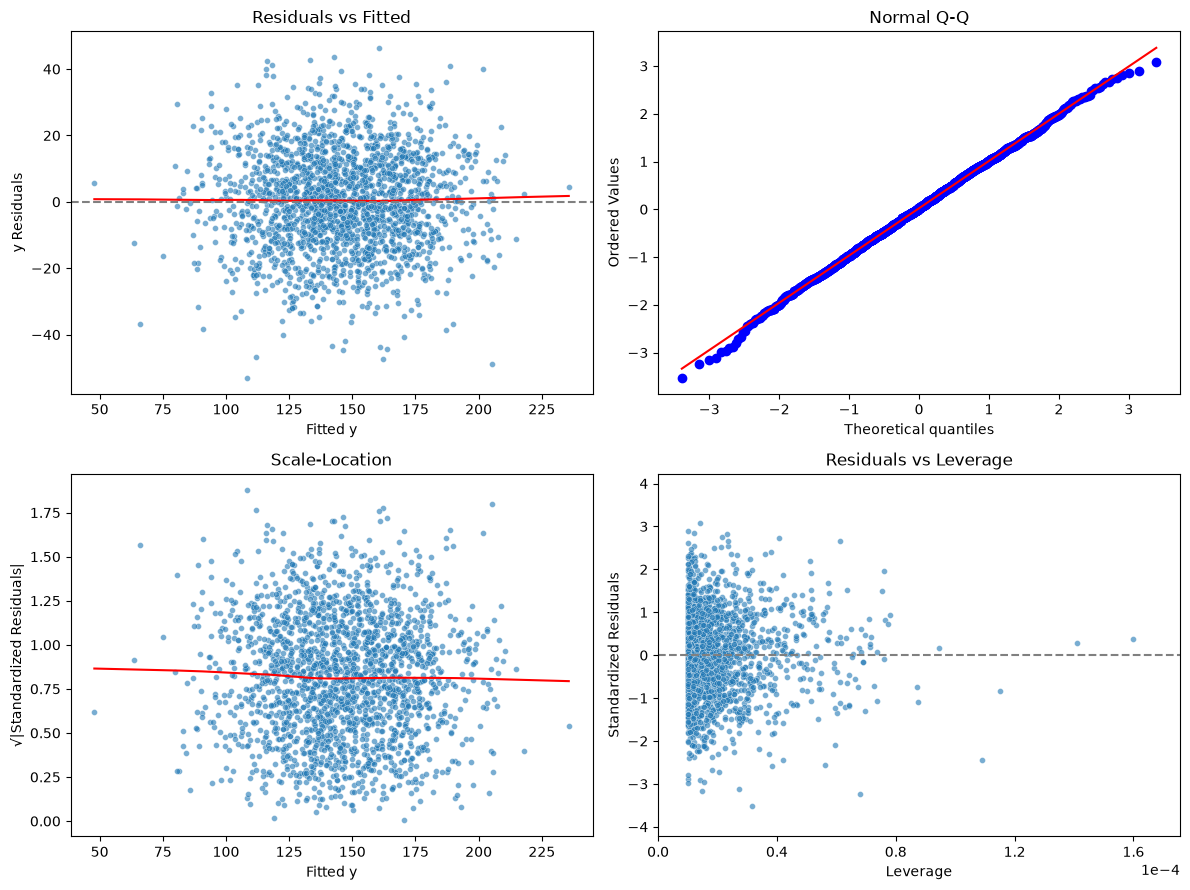

In [154]:
# Diagnostics plot

lm_custom.plot_diagnostics()

OLS Summary:
------------------------------------------------------------------------------------------------------------
Response variable:   y
Predictors:          1
Observations used:   41
Rows removed:        0
------------------------------------------------------------------------------------------------------------
Coefficient Estimates
Term                  Estimate    Std. Error     t value       P-value                        95% CI
------------------------------------------------------------------------------------------------------------
Intercept             146.4447       15.8913      9.2154     2.456e-11          (114.3014, 178.5879)
x                      -0.0518        0.2955     -0.1755        0.8616             (-0.6495, 0.5458)
------------------------------------------------------------------------------------------------------------
Residual standard error: 25.3973 on 39 degrees of freedom
R-squared: 0.0008, Adjusted R-squared: -0.0248
F-statistic: 0.0308 on 1 and

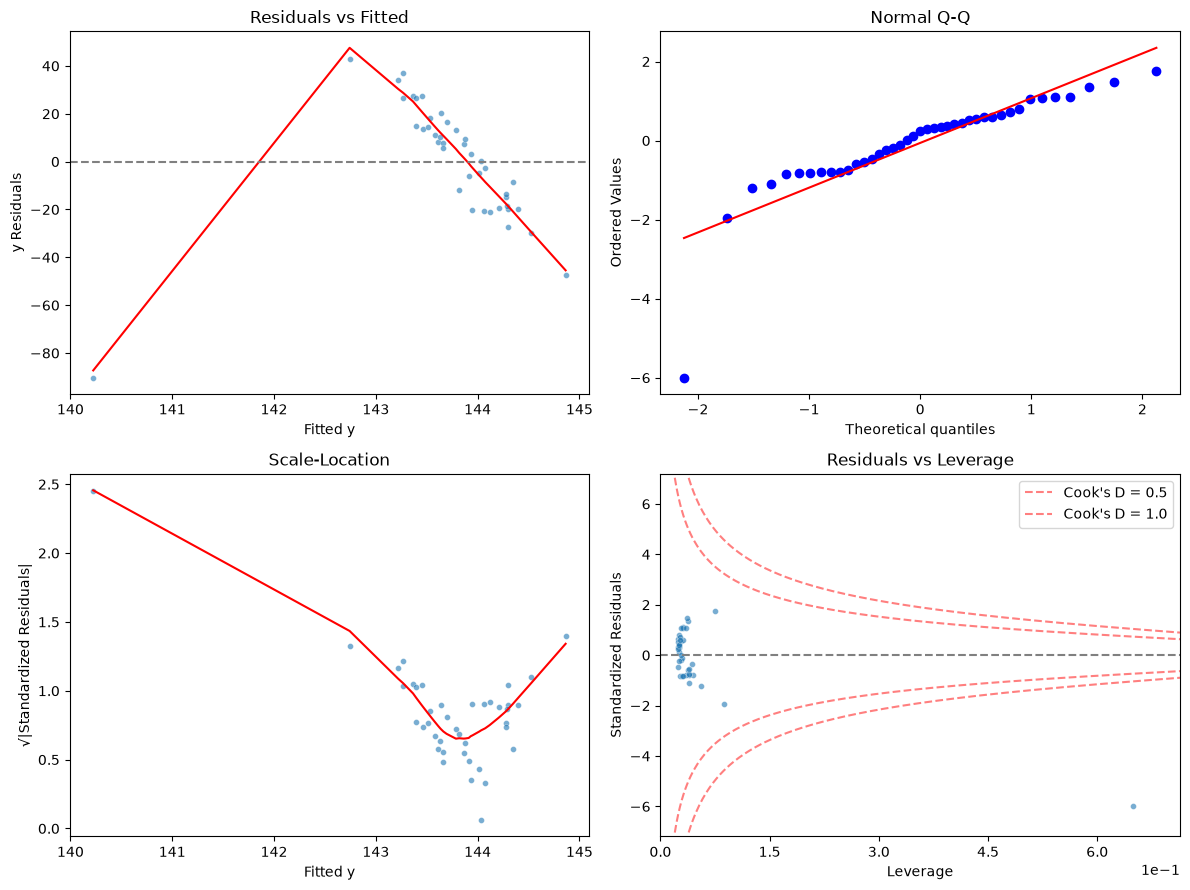

In [155]:
# Plot_Diagonostics with an infulential observation

rng = np.random.default_rng(42)
x = rng.normal(50, 10, 40)
y = 20 + 2.5 * x + rng.normal(0, 10, 40)
x = np.append(x, 120)
y = np.append(y, 50)
df_influential = pd.DataFrame({"x": x, "y": y})
test_model = lm_manual(
    df_influential["x"],
    df_influential["y"]
)
# Generate diagnostic plots
test_model.plot_diagnostics()

#### **Test #5** results:

My custom lm_manual class successfully generated regression plots and all four diagnostic plots: Residuals vs. Fitted, Normal Q-Q, Scale-Location, and Residuals vs. Leverage.

The plots displayed the expected patterns for normally distributed synthetic data. Additional testing with an intentionally influential observation demonstrated that the diagnostic plots correctly visualized unusual residuals, high leverage, and Cook's distance contours at 0.5 and 1.0.

**Conclusion:** Test #5 passed. My custom implementation successfully generates regression and diagnostic plots for both standard and influential-observation datasets, with appropriate visualization of residual patterns, normality, variance, leverage, and Cook's distance.

#### Multiple Linear model test

For the next few tests we are going to be testing on a multiple linear model with three predictors

#### **Test 1:** Compare summaries of both lm_manual and statsmodels

In [156]:
# Generate synthetic multiple regression data

rng = np.random.default_rng(42)
n = 10_000
x1 = rng.normal(50, 10, n)
x2 = rng.normal(20, 5, n)
x3 = rng.normal(5, 2, n)
error = rng.normal(0, 15, n)
y = 20 + 2.5*x1 - 1.8*x2 + 4*x3 + error
df_multiple = pd.DataFrame({"x1": x1,"x2": x2,"x3": x3,"y": y})
X = df_multiple[["x1", "x2", "x3"]]
y = df_multiple["y"]
df_multiple.head()

,x1,x2,x3,y
0,53.047171,20.881385,1.683599,106.594414
1,39.600159,24.495617,6.782414,101.326980
2,57.504512,12.638647,4.883936,140.351973
3,59.405647,18.573509,3.800182,139.552190
4,30.489648,24.145766,4.498365,67.092330


In [157]:
# Statsmodels regression summary

X_sm = sm.add_constant(X)
sm_multi = sm.OLS(y, X_sm).fit()
sm_multi.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.775
Model:                            OLS   Adj. R-squared:                  0.775
Method:                 Least Squares   F-statistic:                 1.145e+04
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:25:39   Log-Likelihood:                -41324.
No. Observations:               10000   AIC:                         8.266e+04
Df Residuals:                    9996   BIC:                         8.269e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         19.9607      1.055     18.928      0.000      17.893      22.028
x1             2.4971      0.015    166.563      0.000       2.468       2.526
x2            -1.7973      0.030    -59.737      0.000      -1.856      -1.738
x3             4.0053      0.075     53.262      0.000       3.858       4.153
==============================================================================
Omnibus:                        0.569   Durbin-Watson:                   2.015
Prob(Omnibus):                  0.752   Jarque-Bera (JB):                0.576
Skew:                           0.018   Prob(JB):                        0.750
Kurtosis:                       2.994   Cond. No.                         384.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [158]:
# lm_manual summary

my_multi = lm_manual(X, y)

OLS Summary:
------------------------------------------------------------------------------------------------------------
Response variable:   y
Predictors:          3
Observations used:   10000
Rows removed:        0
------------------------------------------------------------------------------------------------------------
Coefficient Estimates
Term                  Estimate    Std. Error     t value       P-value                        95% CI
------------------------------------------------------------------------------------------------------------
Intercept              19.9607        1.0546     18.9276     1.581e-78            (17.8935, 22.0279)
x1                      2.4971        0.0150    166.5627             0              (2.4677, 2.5265)
x2                     -1.7973        0.0301    -59.7372             0            (-1.8563, -1.7383)
x3                      4.0053        0.0752     53.2624             0              (3.8579, 4.1527)
-------------------------------------

In [159]:
comparison_multi = pd.DataFrame({
    "My Class": [
        my_multi.R_squared,
        my_multi.adjusted_r_squared,
        my_multi.rse,
        my_multi.f_stat,
        my_multi.p_value
    ],
    "Statsmodels": [
        sm_multi.rsquared,
        sm_multi.rsquared_adj,
        np.sqrt(sm_multi.mse_resid),
        sm_multi.fvalue,
        sm_multi.f_pvalue
    ]
}, index=[
    "R-squared",
    "Adjusted R-squared",
    "Residual Standard Error",
    "F-statistic",
    "P-value"
])
comparison_multi

,My Class,Statsmodels
R-squared,0.774649,0.774649
Adjusted R-squared,0.774582,0.774582
Residual Standard Error,15.084714,15.084714
F-statistic,11453.835268,11453.835268
P-value,0.000000,0.000000


#### **Test #1** results:

Both my custom lm_manual class and the Statsmodels OLS implementation produced matching regression statistics when fitted using the same multiple linear regression dataset containing three independent variables.

The R-squared, adjusted R-squared, residual standard error, F-statistic, and p-value were identical to six decimal places between both models.

**Conclusion:** Test #6 passed for the regression statistics examined. My custom implementation produces results consistent with Statsmodels for multiple linear regression.

#### **Test #2:** Compare both of summaries of lm_manual and statsmodels with missing values

In [160]:
# Intoduce some missing values

df_multi_missing = df_multiple.copy()
rng = np.random.default_rng(42)
df_multi_missing.loc[rng.random(len(df_multi_missing)) < 0.10, "x1"] = np.nan
df_multi_missing.loc[rng.random(len(df_multi_missing)) < 0.05, "x2"] = np.nan
df_multi_missing.loc[rng.random(len(df_multi_missing)) < 0.08, "x3"] = np.nan
df_multi_missing.loc[rng.random(len(df_multi_missing)) < 0.03, "y"] = np.nan
X_missing = df_multi_missing[["x1", "x2", "x3"]]
y_missing = df_multi_missing["y"]

In [161]:
# Statsmodels

X_sm_missing = sm.add_constant(X_missing)
sm_multi_missing = sm.OLS(y_missing,X_sm_missing,missing="drop").fit()
sm_multi_missing.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.774
Model:                            OLS   Adj. R-squared:                  0.774
Method:                 Least Squares   F-statistic:                     8756.
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:25:39   Log-Likelihood:                -31610.
No. Observations:                7655   AIC:                         6.323e+04
Df Residuals:                    7651   BIC:                         6.325e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         20.5578      1.199     17.140      0.000      18.207      22.909
x1             2.4959      0.017    145.795      0.000       2.462       2.529
x2            -1.8153      0.034    -53.302      0.000      -1.882      -1.749
x3             3.9857      0.086     46.463      0.000       3.818       4.154
==============================================================================
Omnibus:                        2.938   Durbin-Watson:                   2.016
Prob(Omnibus):                  0.230   Jarque-Bera (JB):                2.956
Skew:                           0.039   Prob(JB):                        0.228
Kurtosis:                       2.942   Cond. No.                         383.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [162]:
# Lm_manual

my_multi_missing = lm_manual(X_missing, y_missing)


OLS Summary:
------------------------------------------------------------------------------------------------------------
Response variable:   y
Predictors:          3
Observations used:   7655
Rows removed:        2345
------------------------------------------------------------------------------------------------------------
Coefficient Estimates
Term                  Estimate    Std. Error     t value       P-value                        95% CI
------------------------------------------------------------------------------------------------------------
Intercept              20.5578        1.1994     17.1403     1.184e-64            (18.2067, 22.9089)
x1                      2.4959        0.0171    145.7950             0              (2.4624, 2.5295)
x2                     -1.8153        0.0341    -53.3019             0            (-1.8820, -1.7485)
x3                      3.9857        0.0858     46.4627             0              (3.8175, 4.1538)
-----------------------------------

In [163]:
comparison_multi_missing = pd.DataFrame({
    "My Class": [
        my_multi_missing.R_squared,
        my_multi_missing.adjusted_r_squared,
        my_multi_missing.rse,
        my_multi_missing.f_stat,
        my_multi_missing.p_value
    ],
    "Statsmodels": [
        sm_multi_missing.rsquared,
        sm_multi_missing.rsquared_adj,
        np.sqrt(sm_multi_missing.mse_resid),
        sm_multi_missing.fvalue,
        sm_multi_missing.f_pvalue
    ]
}, index=[
    "R-squared",
    "Adjusted R-squared",
    "Residual Standard Error",
    "F-statistic",
    "P-value"
])
comparison_multi_missing.round(6)


,My Class,Statsmodels
R-squared,0.774432,0.774432
Adjusted R-squared,0.774344,0.774344
Residual Standard Error,15.038141,15.038141
F-statistic,8755.942814,8755.942814
P-value,0.000000,0.000000


#### **Test #2** results:

Both my custom lm_manual class and the Statsmodels OLS implementation produced matching regression results when fitted using the same multiple linear regression dataset containing missing values.

The R-squared, adjusted R-squared, residual standard error, F-statistic, and p-value were identical to six decimal places between both models.

**Conclusion:** Test #7 passed for the regression statistics examined. My custom implementation produces results consistent with Statsmodels when performing multiple linear regression on data containing missing values.

#### **Test #3:** Compare multiple regression prediction intervals of both lm_manual and statsmodels

In [164]:
# New X values
X_new = pd.DataFrame({
    "x1": [20, 30, 40, 50, 60, 70, 80],
    "x2": [10, 15, 20, 25, 30, 35, 40],
    "x3": [2, 3, 4, 5, 6, 7, 8]
})
# My class
my_pred = my_multi.predict(X_new)
my_ci = my_multi.predict(X_new, interval="CONFIDENCE")
my_pi = my_multi.predict(X_new, interval="PREDICTION")
# Statsmodels
X_sm_new = sm.add_constant(X_new, has_constant="add")
sm_results = sm_multi.get_prediction(X_sm_new).summary_frame(alpha=0.05)
# Comparison DataFrame
comparison = pd.DataFrame({
    "x1": X_new["x1"],
    "x2": X_new["x2"],
    "x3": X_new["x3"],

    "My Prediction": np.asarray(my_pred).ravel(),
    "SM Prediction": sm_results["mean"].to_numpy(),

    "My CI Lower": my_ci["Lower Bound"].to_numpy(),
    "SM CI Lower": sm_results["mean_ci_lower"].to_numpy(),

    "My CI Upper": my_ci["Upper Bound"].to_numpy(),
    "SM CI Upper": sm_results["mean_ci_upper"].to_numpy(),

    "My PI Lower": my_pi["Lower Bound"].to_numpy(),
    "SM PI Lower": sm_results["obs_ci_lower"].to_numpy(),

    "My PI Upper": my_pi["Upper Bound"].to_numpy(),
    "SM PI Upper": sm_results["obs_ci_upper"].to_numpy()
})

comparison.round(4)


,x1,x2,x3,My Prediction,SM Prediction,My CI Lower,SM CI Lower,My CI Upper,SM CI Upper,My PI Lower,SM PI Lower,My PI Upper,SM PI Upper
0,20,10,2,59.9403,59.9403,58.7407,58.7407,61.1398,61.1398,30.3469,30.3469,89.5337,89.5337
1,30,15,3,79.9301,79.9301,79.1437,79.1437,80.7165,80.7165,50.3505,50.3505,109.5096,109.5096
2,40,20,4,99.9199,99.9199,99.4774,99.4774,100.3623,100.3623,70.3475,70.3475,129.4923,129.4923
3,50,25,5,119.9097,119.9097,119.4963,119.4963,120.3231,120.3231,90.3377,90.3377,149.4816,149.4816
4,60,30,6,139.8995,139.8995,139.1620,139.1620,140.6369,140.6369,110.3212,110.3212,169.4777,169.4777
5,70,35,7,159.8893,159.8893,158.7427,158.7427,161.0359,161.0359,130.2980,130.2980,189.4806,189.4806
6,80,40,8,179.8791,179.8791,178.3032,178.3032,181.4549,181.4549,150.2680,150.2680,209.4901,209.4901


#### **Test #3** results:

Both my custom lm_manual class and the Statsmodels OLS implementation produced matching point predictions, confidence intervals, and prediction intervals when evaluated using the same multiple linear regression model containing three independent variables.

All predicted values, confidence interval bounds, and prediction interval bounds were identical to four decimal places across the seven tested observations.

**Conclusion:** Test #8 passed. My custom implementation accurately calculates point predictions, confidence intervals, and prediction intervals consistent with Statsmodels for multiple linear regression.

#### **Test #4:** Compare multiple regression diagnostics of both statsmodels and lm_manual

In [165]:
# My class diagnostics
my_fitted = my_multi.fitted_y
my_resid = my_multi.residuals
my_leverage = my_multi.leverage
my_std_resid = my_multi.std_residuals
my_cooks = my_multi.cooks_distance

# Statsmodels diagnostics
sm_influence = sm_multi.get_influence()

sm_fitted = sm_multi.fittedvalues
sm_resid = sm_multi.resid
sm_leverage = sm_influence.hat_matrix_diag
sm_std_resid = sm_influence.resid_studentized_internal
sm_cooks = sm_influence.cooks_distance[0]


# Comparison DataFrame
diagnostics_comparison = pd.DataFrame({
    "My Fitted": np.asarray(my_fitted).ravel(),
    "SM Fitted": np.asarray(sm_fitted).ravel(),

    "My Residual": np.asarray(my_resid).ravel(),
    "SM Residual": np.asarray(sm_resid).ravel(),

    "My Leverage": np.asarray(my_leverage).ravel(),
    "SM Leverage": np.asarray(sm_leverage).ravel(),

    "My Std Residual": np.asarray(my_std_resid).ravel(),
    "SM Std Residual": np.asarray(sm_std_resid).ravel(),

    "My Cook's D": np.asarray(my_cooks).ravel(),
    "SM Cook's D": np.asarray(sm_cooks).ravel()
})

diagnostics_comparison.head(5).round(6)


,My Fitted,SM Fitted,My Residual,SM Residual,My Leverage,SM Leverage,My Std Residual,SM Std Residual,My Cook's D,SM Cook's D
0,121.638107,121.638107,-15.043693,-15.043693,0.000389,0.000389,-0.997475,-0.997475,0.000097,0.000097
1,101.985737,101.985737,-0.658757,-0.658757,0.000356,0.000356,-0.043678,-0.043678,0.000000,0.000000
2,160.401744,160.401744,-20.049771,-20.049771,0.000377,0.000377,-1.329395,-1.329395,0.000166,0.000166
3,150.141473,150.141473,-10.589283,-10.589283,0.000235,0.000235,-0.702070,-0.702070,0.000029,0.000029
4,70.716276,70.716276,-3.623946,-3.623946,0.000540,0.000540,-0.240305,-0.240305,0.000008,0.000008


In [166]:
# VIF comparison

my_vif = my_multi.vif()
# Statsmodels VIF
sm_vif = pd.DataFrame({
    "Predictor": X.columns,
    "VIF": [
        variance_inflation_factor(X_sm.values, i)
        for i in range(1, X_sm.shape[1])
    ]
})
# Comparison DataFrame
vif_comparison = pd.DataFrame({
    "Predictor": my_vif["Predictor"],
    "My Class": my_vif["VIF"],
    "Statsmodels": sm_vif["VIF"]
})

vif_comparison.round(4)


,Predictor,My Class,Statsmodels
0,x1,1.0002,1.0002
1,x2,1.0003,1.0003
2,x3,1.0002,1.0002


#### **Test #4** results:

Both my custom lm_manual class and the Statsmodels OLS implementation produced matching regression diagnostic statistics when fitted using the same multiple linear regression dataset.

The fitted values, residuals, leverage, standardized residuals, and Cook's distances were identical to six decimal places for the observations examined. Additionally, the variance inflation factors (VIF) matched to four decimal places across all three independent variables.

**Conclusion:** Test #4 passed for the displayed results. My custom implementation accurately calculates regression diagnostics and VIF values consistent with Statsmodels for multiple linear regression.

#### **Test #5:** Test plot_diagnostics with a multiple regression model

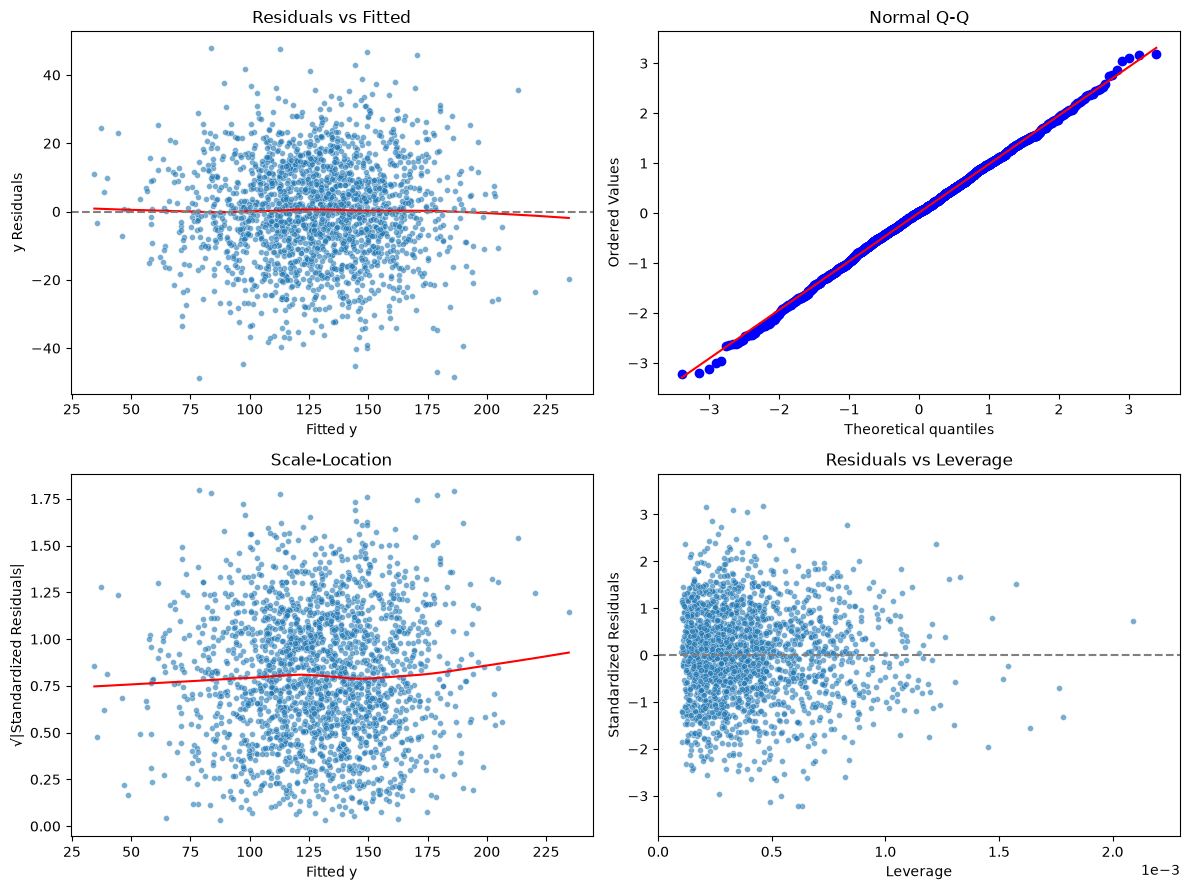

In [167]:
# Plot_diagnostics test
my_multi.plot_diagnostics()

OLS Summary:
------------------------------------------------------------------------------------------------------------
Response variable:   y
Predictors:          3
Observations used:   61
Rows removed:        0
------------------------------------------------------------------------------------------------------------
Coefficient Estimates
Term                  Estimate    Std. Error     t value       P-value                        95% CI
------------------------------------------------------------------------------------------------------------
Intercept             116.7470       11.0030     10.6105     4.097e-15           (94.7139, 138.7800)
x1                      1.7453        0.2565      6.8030     6.772e-09              (1.2315, 2.2590)
x2                     -4.8687        0.4812    -10.1172     2.449e-14            (-5.8323, -3.9050)
x3                      3.8058        1.1614      3.2768       0.00179              (1.4801, 6.1316)
----------------------------------------

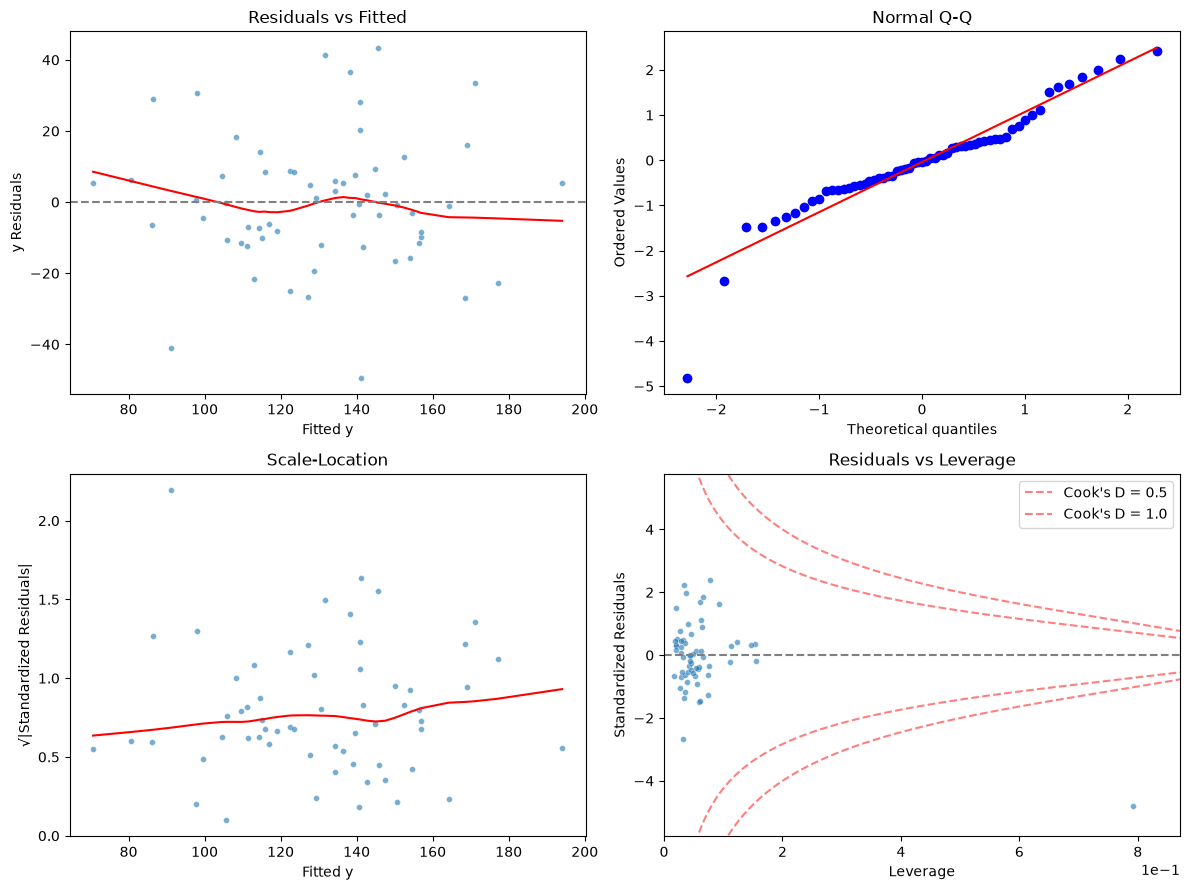

In [168]:
# Generate multiple regression data with an influential observation
rng = np.random.default_rng(42)
n = 60
x1 = rng.normal(50, 10, n)
x2 = rng.normal(20, 5, n)
x3 = rng.normal(5, 2, n)
error = rng.normal(0, 15, n)
y = 20 + 2.5*x1 - 1.8*x2 + 4*x3 + error
# Add an influential observation
x1 = np.append(x1, 120)
x2 = np.append(x2, 60)
x3 = np.append(x3, 15)
y = np.append(y, 50)
df_multi_influential = pd.DataFrame({
    "x1": x1,
    "x2": x2,
    "x3": x3,
    "y": y
})
X_influential = df_multi_influential[["x1", "x2", "x3"]]
y_influential = df_multi_influential["y"]
my_multi_influential = lm_manual(X_influential, y_influential)
# Generate diagnostic plots
my_multi_influential.plot_diagnostics()

#### **Test #10** results:

My custom lm_manual class successfully generated all four regression diagnostic plots for multiple linear regression using both a standard synthetic dataset and a dataset containing an intentionally influential observation.

The standard dataset exhibited approximately normal residuals, relatively constant variance, and low leverage values. The influential dataset demonstrated the effects of an extreme observation, including deviations from normality, high leverage, and visible Cook's distance contours at 0.5 and 1.0.

**Conclusion:** Test #10 passed visual inspection. My custom implementation successfully generates multiple linear regression diagnostic plots and appropriately visualizes residual patterns, normality, variance, leverage, and influential observations.

## Overall Testing Conclusion

My custom lm_manual class successfully completed all 10 validation tests for simple and multiple linear regression. The implementation was compared against Statsmodels OLS using synthetic datasets, including datasets containing missing values and influential observations.

The results demonstrated consistent calculations for regression coefficients, standard errors, p-values, R-squared, adjusted R-squared, residual standard error, and F-statistics. Point predictions, confidence intervals, prediction intervals, and regression diagnostics also matched Statsmodels to the tested numerical precision. Additionally, variance inflation factors (VIF) were consistent between both implementations.

The class also successfully generated regression visualizations and diagnostic plots, including Residuals vs. Fitted, Normal Q-Q, Scale-Location, and Residuals vs. Leverage. Testing with influential observations confirmed that the plots appropriately displayed unusual residuals, high leverage, and Cook's distance contours.

**Conclusion:** All 10 tests produced satisfactory results, demonstrating that my custom lm_manual class performs consistently with Statsmodels for the datasets examined. Although additional edge-case testing could improve robustness, the implementation is sufficiently validated for exploratory data analysis and further practical applications.